In [1]:
from pathlib import Path
import matplotlib.pyplot as plt

DATA_DIR = Path(r"D:\F20DL CW UG\Insurance-Fraud-Detection\Insurance-Fraud-Detection")
RESULTS = Path("../results/images")

# list of folder names used to loop over them instead of typing each one.
CLASSES = ["Fraud", "Non-Fraud"]
SPLITS = ["train", "test"]

print(DATA_DIR.exists())

True


In [2]:
# Created a function to count images in a folder.
def count_images(folder):
    n = 0 # starts the counter at zero.
    for f in folder.iterdir(): # goes through every file in the folder, one at a time.
        if f.suffix.lower() in [".jpg", ".jpeg", ".png"]: # checks if the file is an image.
            n = n + 1 # increments the counter by 1.
    return n

# Counts the number of images in each folder and print the results.
counts = {}
for split in SPLITS: # loops over each split (train, test)
    counts[split] = {}
    for c in CLASSES: # loops over each class (Fraud, Non-Fraud)
        counts[split][c] = count_images(DATA_DIR / split / c)

print(counts) 

# Calculates the percentage of fraud images in train and test sets.
train_fraud_percentage = counts["train"]["Fraud"] / (counts["train"]["Fraud"] + counts["train"]["Non-Fraud"]) * 100
test_fraud_percentage = counts["test"]["Fraud"] / (counts["test"]["Fraud"] + counts["test"]["Non-Fraud"]) * 100
print(f"Fraud is {train_fraud_percentage:.1f}% of train and {test_fraud_percentage:.1f}% of test") 

{'train': {'Fraud': 200, 'Non-Fraud': 5000}, 'test': {'Fraud': 93, 'Non-Fraud': 1323}}
Fraud is 3.8% of train and 6.6% of test


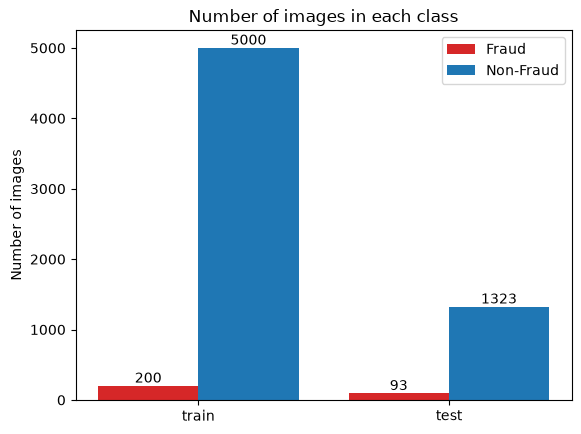

In [5]:
# Plots the number of images in each class for train and test sets (bar chart)

x = [0, 1] # sets two positions on the chart, one for train and one for test
fraud = [counts["train"]["Fraud"], counts["test"]["Fraud"]]
non_fraud = [counts["train"]["Non-Fraud"], counts["test"]["Non-Fraud"]]

bars1 = plt.bar([i - 0.2 for i in x], fraud, width=0.4, label="Fraud", color="tab:red") # plots bars for fraud images
bars2 = plt.bar([i + 0.2 for i in x], non_fraud, width=0.4, label="Non-Fraud", color="tab:blue") # plots bars for non-fraud images
plt.xticks(x, ["train", "test"]) # sets the x-axis labels
plt.ylabel("Number of images") # sets the y-axis label
plt.title("Number of images in each class") # sets the title
plt.legend() # displays the legend
plt.bar_label(bars1) # adds labels to the bars for fraud images
plt.bar_label(bars2) # adds labels to the bars for non-fraud images
plt.savefig(RESULTS / "class_counts.png", dpi=150, bbox_inches="tight") # saves the plot
plt.show() # displays the plot